# Whereby Analytics — Análise Exploratória

**Disciplina:** Big Data em Python · **Fonte:** API REST do Whereby Embedded (dados reais, anonimizados)

Este notebook usa **apenas** os datasets públicos e anonimizados de `data/public/`:

| Arquivo | Grão | Principais colunas |
|---|---|---|
| `sessions.parquet` | 1 linha por aula realizada | data, hora (America/Sao_Paulo), duração, nº de participantes |
| `participations.parquet` | 1 linha por conexão de um participante | pessoa (Teacher/Student NNN), entrada relativa ao início, permanência |
| `rooms.parquet` | 1 linha por sala | nº de sessões, duração média |
| `quality_report.json` | — | ausentes, duplicatas e inconsistências tratadas |

Nenhum nome, e-mail, ID original ou link aparece aqui (ver `docs/01_relatorio_viabilidade.md`).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PUBLIC = Path(os.getenv("WA_PUBLIC_DIR", ROOT / "data" / "public"))
FIG = Path(os.getenv("WA_FIG_DIR", ROOT / "docs" / "figures"))
FIG.mkdir(parents=True, exist_ok=True)

# Paleta validada (CVD-safe): série 1 azul, série 2 laranja; sequencial em azul.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
sns.set_theme(style="white", rc={
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "font.size": 10,
})
DIAS = {"Monday": "Seg", "Tuesday": "Ter", "Wednesday": "Qua", "Thursday": "Qui",
        "Friday": "Sex", "Saturday": "Sáb", "Sunday": "Dom"}
ORDEM_DIAS = list(DIAS.values())


def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")
    plt.show()

## 1. Importação dos dados

In [2]:
s = pd.read_parquet(PUBLIC / "sessions.parquet")
p = pd.read_parquet(PUBLIC / "participations.parquet")
rooms = pd.read_parquet(PUBLIC / "rooms.parquet")
quality = json.loads((PUBLIC / "quality_report.json").read_text())

s["date"] = pd.to_datetime(s["date"])
s["dia"] = pd.Categorical(s["weekday"].map(DIAS), ORDEM_DIAS, ordered=True)
print(f"Sessões: {len(s):,} | Participações (conexões): {len(p):,} | Salas: {len(rooms)}")
print(f"Período: {s['date'].min():%d/%m/%Y} a {s['date'].max():%d/%m/%Y}")
s.head()

Sessões: 1,781 | Participações (conexões): 13,506 | Salas: 163
Período: 17/08/2026 a 17/11/2026


,session_id,room_id,date,year_week,month,weekday,start_hour,end_hour,slot_offset_min,duration_min,api_unique_participants,participant_minutes,room_mode,n_segments,n_people,n_unidentified_segments,n_teachers,n_students,is_short,dia
0,Session 00001,Room 104,2026-08-17,2026-W34,2026-08,Monday,8,8,0.5,50.8,6,277,group,13,6,0,1,5,False,Seg
1,Session 00002,Room 059,2026-08-17,2026-W34,2026-08,Monday,8,8,1.0,51.1,6,287,group,6,6,0,1,5,False,Seg
2,Session 00003,Room 089,2026-08-17,2026-W34,2026-08,Monday,12,12,0.2,54.1,9,451,group,12,9,0,1,8,False,Seg
3,Session 00004,Room 062,2026-08-17,2026-W34,2026-08,Monday,12,12,0.5,53.7,9,410,group,10,8,0,1,7,False,Seg
4,Session 00005,Room 007,2026-08-17,2026-W34,2026-08,Monday,12,12,1.5,50.8,3,150,group,3,3,0,1,2,False,Seg


In [3]:
p.head()

,session_id,person_id,role,join_offset_min,stay_min,segment_n,is_reconnection
0,Session 00598,Student 118,student,0.0,50.3,1,False
1,Session 00598,Teacher 003,teacher,0.0,50.3,1,False
2,Session 00598,Student 027,student,0.1,50.4,1,False
3,Session 00598,Student 120,student,0.9,49.4,1,False
4,Session 00598,Student 470,student,0.9,49.4,1,False


## 2. Qualidade dos dados: ausentes, duplicatas e inconsistências

A limpeza estrutural é feita em `src/wa/build_dataset.py` **antes** da anonimização
(precisa dos IDs originais para detectar duplicatas). O relatório abaixo documenta
cada regra aplicada; em seguida verificamos o resultado nos dados públicos.

In [4]:
regras = {
    "duplicates_removed.sessions": "Sessões duplicadas removidas (mesmo roomSessionId)",
    "duplicates_removed.participations": "Conexões duplicadas removidas (mesma sessão, participante e entrada)",
    "inconsistencies.sessions_ongoing_without_end": "Sessões sem horário de fim (em andamento) — excluídas",
    "inconsistencies.sessions_invalid_duration": "Sessões com duração ≤ 0 ou > 6 h — excluídas",
    "inconsistencies.participations_orphan_or_excluded_session": "Conexões de sessões excluídas — removidas",
    "inconsistencies.participations_without_left_imputed": "Conexões sem horário de saída — imputado o fim da sessão",
    "inconsistencies.participations_left_before_join": "Conexões com saída antes da entrada — removidas",
}
linhas = []
for chave, desc in regras.items():
    grupo, campo = chave.split(".")
    linhas.append({"Regra": desc, "Registros afetados": quality[grupo][campo]})
tab_qualidade = pd.DataFrame(linhas)
print("Brutos:", quality["raw"], "→ Finais:", {k: quality["final"][k] for k in ("sessions", "participations")})
tab_qualidade

Brutos: {'sessions': 1783, 'participations': 13517} → Finais: {'sessions': 1781, 'participations': 13506}


,Regra,Registros afetados
0,Sessões duplicadas removidas (mesmo roomSessio...,0
1,"Conexões duplicadas removidas (mesma sessão, p...",0
2,Sessões sem horário de fim (em andamento) — ex...,2
3,Sessões com duração ≤ 0 ou > 6 h — excluídas,0
4,Conexões de sessões excluídas — removidas,7
5,Conexões sem horário de saída — imputado o fim...,4
6,Conexões com saída antes da entrada — removidas,4


In [5]:
for nome, df in (("sessões", s), ("participações", p)):
    aus = df.isna().sum()
    aus = aus[aus > 0]
    print(f"Valores ausentes nos dados públicos ({nome}):", aus.to_dict() if len(aus) else "nenhum")
print("\nDuplicatas restantes:",
      s.duplicated("session_id").sum(), "sessões,",
      p.duplicated(["session_id", "person_id", "join_offset_min"]).sum(), "participações")
print("Conexões sem pessoa identificável (nome vazio):", p["person_id"].isna().sum())
print("Durações negativas:", (s["duration_min"] < 0).sum(), "| Permanências negativas:", (p["stay_min"] < 0).sum())

Valores ausentes nos dados públicos (sessões): nenhum
Valores ausentes nos dados públicos (participações): nenhum

Duplicatas restantes: 0 sessões, 138 participações
Conexões sem pessoa identificável (nome vazio): 0
Durações negativas: 0 | Permanências negativas: 0


## 3. Análise 1 — Quantidade de aulas por dia, semana e mês

Agosto e novembro estão **parciais** (o período começa em 17/08 e termina em 17/11).

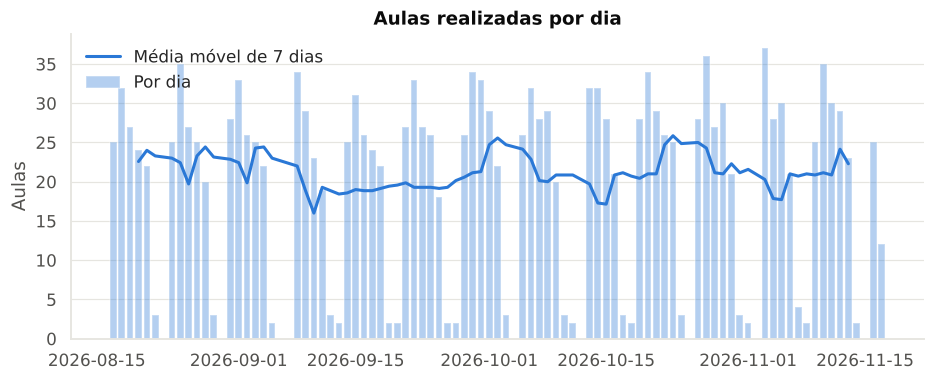

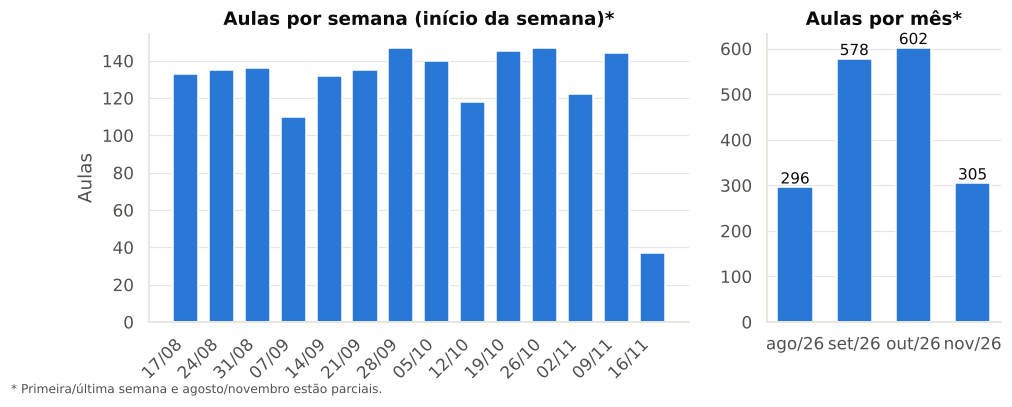

Média por dia útil: 27.0 | por semana completa: 134


In [6]:
por_dia = s.groupby("date").size()
por_semana = s.groupby(s["date"].dt.to_period("W-SUN").dt.start_time).size()
por_mes = s.groupby(s["date"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(por_dia.index, por_dia.values, width=0.8, color=BLUE, alpha=0.35, label="Por dia")
ax.plot(por_dia.rolling(7, center=True).mean(), color=BLUE, lw=2, label="Média móvel de 7 dias")
ax.set(title="Aulas realizadas por dia", ylabel="Aulas", xlabel="")
ax.legend(frameon=False, loc="upper left")
salvar(fig, "01_aulas_por_dia")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [3, 1.3]})
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
rot_sem = [f"{d:%d/%m}" for d in por_semana.index]
axes[0].bar(range(len(por_semana)), por_semana.values, width=0.7, color=BLUE)
axes[0].set_xticks(range(len(por_semana)), rot_sem, rotation=45, ha="right")
axes[0].set(title="Aulas por semana (início da semana)*", ylabel="Aulas")
axes[1].bar([f"{MESES[m.month - 1]}/{m.year % 100}" for m in por_mes.index], por_mes.values, color=BLUE, width=0.6)
for i, v in enumerate(por_mes.values):
    axes[1].text(i, v, f"{v}", ha="center", va="bottom", color=INK)
axes[1].set(title="Aulas por mês*")
fig.text(0, -0.08, "* Primeira/última semana e agosto/novembro estão parciais.", color=MUTED, fontsize=8)
salvar(fig, "02_aulas_semana_mes")
print(f"Média por dia útil: {por_dia[por_dia.index.dayofweek < 5].mean():.1f} | "
      f"por semana completa: {por_semana.iloc[1:-1].mean():.0f}")

## 4. Análise 2 — Duração das aulas

count    1781.0
mean       49.0
std        11.2
min         0.1
25%        48.0
50%        51.2
75%        54.3
max        95.5


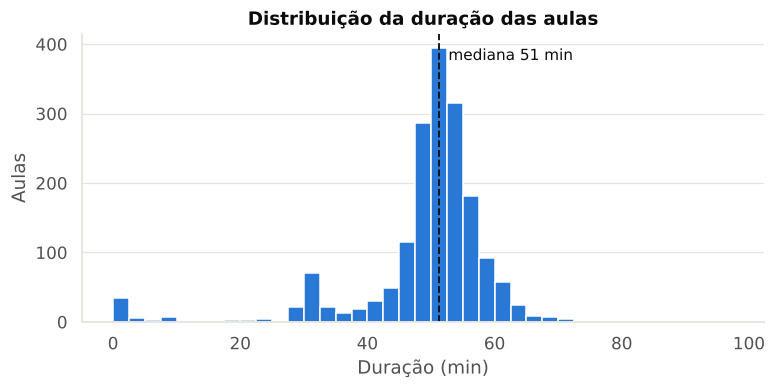

In [7]:
d = s["duration_min"]
print(d.describe().round(1).to_string())
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(d, bins=np.arange(0, d.max() + 3, 2.5), color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(d.median(), color=INK, lw=1.2, ls="--")
ax.text(d.median(), ax.get_ylim()[1] * 0.95, f"  mediana {d.median():.0f} min", color=INK, va="top")
ax.set(title="Distribuição da duração das aulas", xlabel="Duração (min)", ylabel="Aulas")
salvar(fig, "03_duracao")

## 5. Análise 3 — Distribuição dos horários (dia da semana × hora)

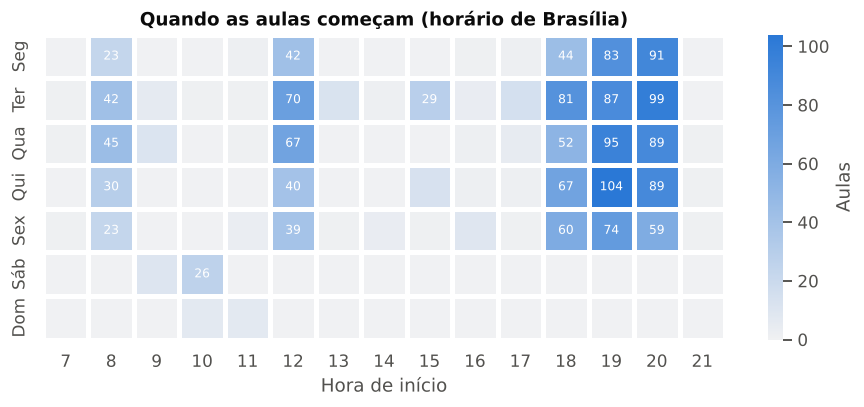

Horários mais frequentes: 19h (25%), 20h (24%), 18h (17%)
Aulas no fim de semana: 2.8%


In [8]:
heat = s.pivot_table(index="dia", columns="start_hour", values="session_id", aggfunc="count", observed=False).fillna(0)
heat = heat.reindex(columns=range(int(s.start_hour.min()), int(s.start_hour.max()) + 1), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(heat, cmap=sns.light_palette(BLUE, as_cmap=True), linewidths=2, linecolor="white",
            cbar_kws={"label": "Aulas"}, ax=ax, annot=np.where(heat >= 20, heat.astype(int).astype(str), ""), fmt="",
            annot_kws={"color": "white", "fontsize": 8})
ax.set(title="Quando as aulas começam (horário de Brasília)", xlabel="Hora de início", ylabel="")
ax.grid(False)
salvar(fig, "04_heatmap_horarios")
top = s["start_hour"].value_counts(normalize=True).head(3)
print("Horários mais frequentes:", ", ".join(f"{h}h ({v:.0%})" for h, v in top.items()))
print("Aulas no fim de semana:", f"{s['dia'].isin(['Sáb', 'Dom']).mean():.1%}")

## 6. Análise 4 — Participantes por aula

`api_unique_participants` vem da API (participantes únicos, inclui o professor).
`n_students` é calculado a partir das conexões anonimizadas.

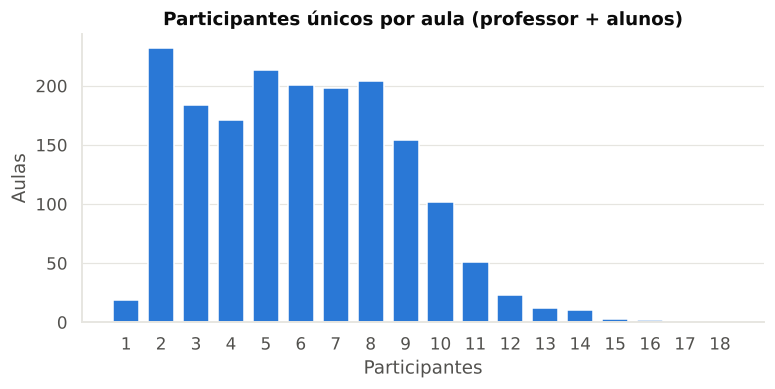

Média: 6.0 | mediana: 6 | aulas individuais (2 pessoas): 13%


In [9]:
cont = s["api_unique_participants"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(cont.index, cont.values, color=BLUE, width=0.75)
ax.set(title="Participantes únicos por aula (professor + alunos)", xlabel="Participantes", ylabel="Aulas")
ax.set_xticks(cont.index)
salvar(fig, "05_participantes_por_aula")
print(f"Média: {s['api_unique_participants'].mean():.1f} | mediana: {s['api_unique_participants'].median():.0f} | "
      f"aulas individuais (2 pessoas): {(s['api_unique_participants'] == 2).mean():.0%}")

## 7. Análise 5 — Tempo de permanência

Uma pessoa pode ter várias conexões na mesma aula (reconexões). Somamos as conexões
para obter a permanência total de cada pessoa em cada aula, e comparamos com a duração da aula.

           stay_min  pct_aula  conexoes
papel                                  
Aluno         48.85      0.96       1.0
Professor     51.10      1.00       1.0


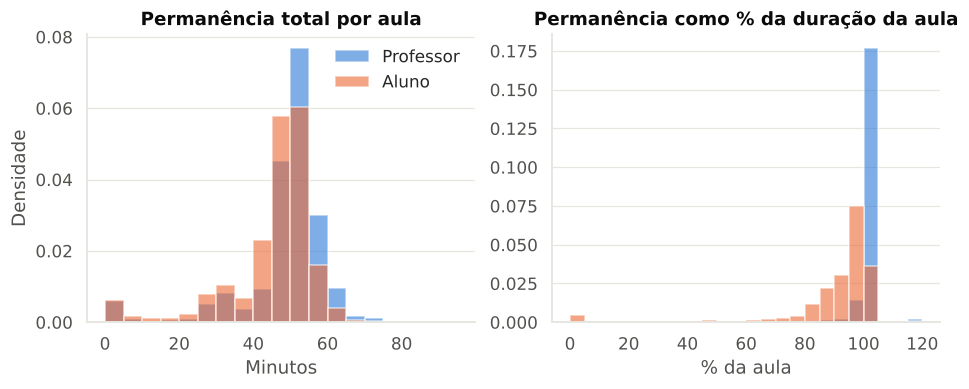

In [10]:
pp = (p.dropna(subset=["person_id"])
        .groupby(["session_id", "person_id", "role"], as_index=False)
        .agg(stay_min=("stay_min", "sum"), first_join=("join_offset_min", "min"), conexoes=("segment_n", "max")))
pp = pp.merge(s[["session_id", "duration_min"]], on="session_id")
pp["pct_aula"] = (pp["stay_min"] / pp["duration_min"]).clip(upper=1.2)
pp["papel"] = pp["role"].map({"teacher": "Professor", "student": "Aluno"})
print(pp.groupby("papel")[["stay_min", "pct_aula", "conexoes"]].median().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for papel, cor in (("Professor", BLUE), ("Aluno", ORANGE)):
    dados = pp.loc[pp["papel"] == papel]
    axes[0].hist(dados["stay_min"], bins=np.arange(0, 100, 5), color=cor, alpha=0.6, label=papel,
                 edgecolor="white", density=True)
    axes[1].hist(dados["pct_aula"] * 100, bins=np.arange(0, 125, 5), color=cor, alpha=0.6, label=papel,
                 edgecolor="white", density=True)
axes[0].set(title="Permanência total por aula", xlabel="Minutos", ylabel="Densidade")
axes[1].set(title="Permanência como % da duração da aula", xlabel="% da aula", ylabel="")
axes[0].legend(frameon=False)
salvar(fig, "06_permanencia")

## 8. Análise 6 — Horário previsto × realizado (aproximação)

A API **não** informa o horário agendado das aulas (as salas são fixas e reutilizadas).
Usamos duas aproximações documentadas:

1. **Início em relação à grade:** as aulas são agendadas em horários cheios ou meia hora;
   `slot_offset_min` mede quantos minutos após o :00/:30 mais próximo a aula começou de fato
   (uma sessão só começa quando há 2 pessoas na sala).
2. **Pontualidade relativa:** quanto tempo depois do professor cada aluno entrou.

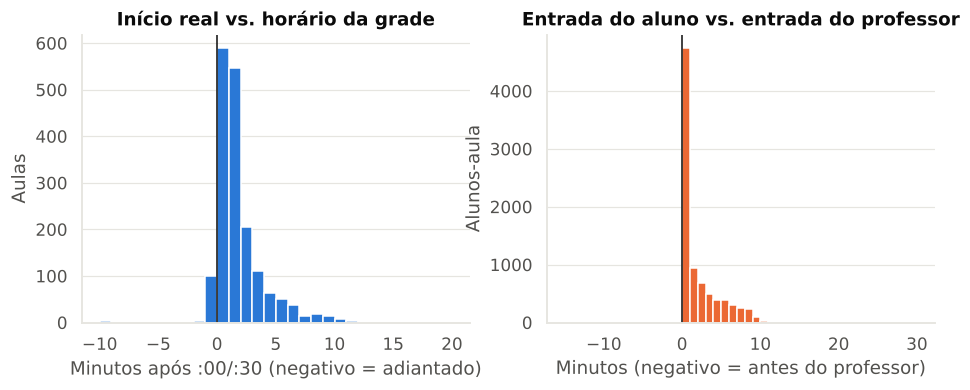

Início após o horário da grade — mediana 1.2 min; 8% das aulas começaram com mais de 5 min de atraso
Alunos que entraram 5+ min depois do professor: 15%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(s["slot_offset_min"], bins=np.arange(-10, 20.5, 1), color=BLUE, edgecolor="white")
axes[0].axvline(0, color=INK, lw=1)
axes[0].set(title="Início real vs. horário da grade", xlabel="Minutos após :00/:30 (negativo = adiantado)",
            ylabel="Aulas")

prof = pp[pp.role == "teacher"].groupby("session_id")["first_join"].min().rename("prof_join")
alunos = pp[pp.role == "student"].join(prof, on="session_id").dropna(subset=["prof_join"])
alunos["atraso_vs_prof"] = alunos["first_join"] - alunos["prof_join"]
axes[1].hist(alunos["atraso_vs_prof"].clip(-15, 30), bins=np.arange(-15, 31, 1), color=ORANGE, edgecolor="white")
axes[1].axvline(0, color=INK, lw=1)
axes[1].set(title="Entrada do aluno vs. entrada do professor", xlabel="Minutos (negativo = antes do professor)",
            ylabel="Alunos-aula")
salvar(fig, "07_previsto_realizado")
print(f"Início após o horário da grade — mediana {s.slot_offset_min.median():.1f} min; "
      f"{(s.slot_offset_min > 5).mean():.0%} das aulas começaram com mais de 5 min de atraso")
if len(alunos):
    print(f"Alunos que entraram 5+ min depois do professor: {(alunos.atraso_vs_prof > 5).mean():.0%}")

## 9. Análise 7 — Aulas muito curtas e comportamentos atípicos

Critérios:
* **Muito curta:** duração < 10 min.
* **Outlier de duração:** fora de [Q1 − 1,5·IQR, Q3 + 1,5·IQR].
* **Sem par:** apenas 1 participante único (incomum: a sessão exige 2 pessoas simultâneas).
* **Instável:** alguma pessoa com 3+ conexões na mesma aula.

                                         Aulas  % do total
Muito curtas (< 10 min)                     51         2.9
Outliers de duração (fora de 39–64 min)    235        13.2
Apenas 1 participante                       19         1.1
Com reconexões frequentes (3+)             497        27.9


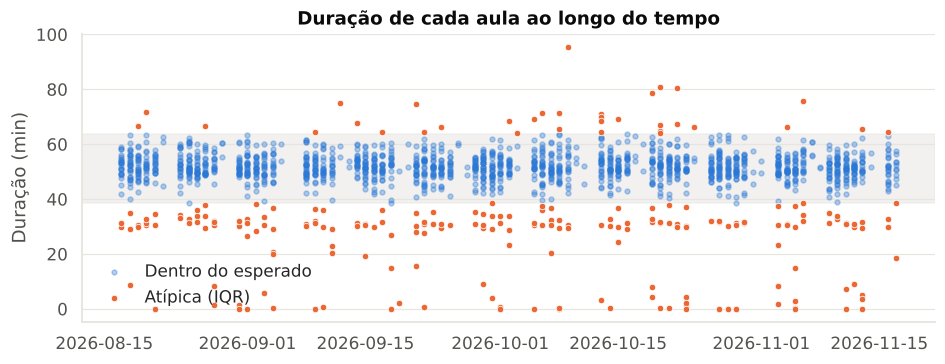

Reconexões:  23.1% das conexões são reconexões


In [12]:
q1, q3 = d.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
instaveis = pp.loc[pp["conexoes"] >= 3, "session_id"].unique()
s["outlier_duracao"] = ~d.between(lim_inf, lim_sup)
s["sem_par"] = s["api_unique_participants"] <= 1
s["instavel"] = s["session_id"].isin(instaveis)
atipicas = pd.Series({
    "Muito curtas (< 10 min)": s["is_short"].sum(),
    f"Outliers de duração (fora de {lim_inf:.0f}–{lim_sup:.0f} min)": s["outlier_duracao"].sum(),
    "Apenas 1 participante": s["sem_par"].sum(),
    "Com reconexões frequentes (3+)": s["instavel"].sum(),
})
print((atipicas.to_frame("Aulas").assign(**{"% do total": (atipicas / len(s) * 100).round(1)})).to_string())

fig, ax = plt.subplots(figsize=(10, 3.4))
normal = s[~s["outlier_duracao"]]
out = s[s["outlier_duracao"]]
ax.scatter(normal["date"], normal["duration_min"], s=10, color=BLUE, alpha=0.35, label="Dentro do esperado")
ax.scatter(out["date"], out["duration_min"], s=18, color=ORANGE, label="Atípica (IQR)", edgecolor="white", lw=0.5)
ax.axhspan(lim_inf, lim_sup, color=GRID, alpha=0.5, zorder=0)
ax.set(title="Duração de cada aula ao longo do tempo", ylabel="Duração (min)")
ax.legend(frameon=False, loc="lower left")
salvar(fig, "08_atipicas")
print("Reconexões: ", f"{p['is_reconnection'].mean():.1%} das conexões são reconexões")

## 10. Análise 8 — Frequência de participação

Identificação **aproximada**: o pseudônimo deriva do nome digitado ao entrar (normalizado),
pois a API não fornece um identificador estável de usuário.

Alunos distintos: 941 | aulas por aluno: média 9.1, mediana 2


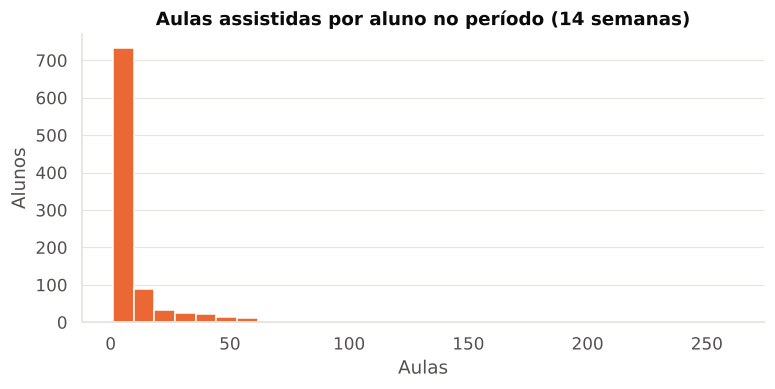

Professores distintos: 29 | aulas por professor: mediana 39


,Aulas ministradas
person_id,
Teacher 008,227
Teacher 004,209
Teacher 003,163
Teacher 002,143
Teacher 005,132
Teacher 017,103
Teacher 007,95
Teacher 009,93
Teacher 022,92


In [13]:
freq = pp[pp.role == "student"].groupby("person_id")["session_id"].nunique()
semanas = s["date"].dt.to_period("W").nunique()
print(f"Alunos distintos: {freq.size} | aulas por aluno: média {freq.mean():.1f}, mediana {freq.median():.0f}")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(freq, bins=np.arange(1, freq.max() + 2) - 0.5 if freq.max() < 40 else 30, color=ORANGE, edgecolor="white")
ax.set(title=f"Aulas assistidas por aluno no período ({semanas} semanas)", xlabel="Aulas", ylabel="Alunos")
salvar(fig, "09_frequencia_alunos")
prof_carga = pp[pp.role == "teacher"].groupby("person_id")["session_id"].nunique().sort_values(ascending=False)
print(f"Professores distintos: {prof_carga.size} | aulas por professor: mediana {prof_carga.median():.0f}")
prof_carga.head(10).to_frame("Aulas ministradas")

## 11. Conclusões

As conclusões abaixo são calculadas a partir dos dados (se a base for atualizada,
os números se atualizam ao reexecutar o notebook).

In [14]:
dia_top = s["dia"].value_counts().idxmax()
h1, h2 = s["start_hour"].value_counts().index[:2]
concl = [
    f"**Volume:** {len(s):,} aulas em {semanas} semanas ({por_semana.iloc[1:-1].mean():.0f} por semana completa), "
    f"concentradas de segunda a sexta ({1 - s['dia'].isin(['Sáb', 'Dom']).mean():.0%}); {dia_top} é o dia mais movimentado.",
    f"**Duração:** padrão muito estável — mediana de {d.median():.0f} min e 50% das aulas entre {q1:.0f} e {q3:.0f} min, "
    f"compatível com aulas de ~50 min.",
    f"**Horários:** picos às {h1}h e {h2}h (horário de Brasília), além de faixas no início da manhã e no almoço — "
    f"perfil de alunos que estudam antes/depois do expediente.",
    f"**Turmas:** média de {s['api_unique_participants'].mean():.1f} participantes por aula; "
    f"{(s['api_unique_participants'] == 2).mean():.0%} são aulas individuais.",
    f"**Pontualidade:** as aulas começam em mediana {s.slot_offset_min.median():.1f} min após o horário da grade; "
    f"{(s.slot_offset_min > 5).mean():.0%} começam com mais de 5 min de atraso.",
    f"**Atípicas:** {s['is_short'].sum()} aulas ({s['is_short'].mean():.1%}) duraram menos de 10 min — candidatas "
    f"a quedas de conexão, testes ou ausência do aluno.",
]
if len(pp):
    med = pp.groupby("papel")["pct_aula"].median()
    concl.append(f"**Permanência:** em mediana, alunos ficam {med.get('Aluno', np.nan):.0%} da aula e professores "
                 f"{med.get('Professor', np.nan):.0%}; {p['is_reconnection'].mean():.0%} das conexões são reconexões.")
from IPython.display import Markdown, display  # noqa: E402

display(Markdown("\n".join(f"{i}. {c}" for i, c in enumerate(concl, 1))))

1. **Volume:** 1,781 aulas em 14 semanas (134 por semana completa), concentradas de segunda a sexta (97%); Ter é o dia mais movimentado.
2. **Duração:** padrão muito estável — mediana de 51 min e 50% das aulas entre 48 e 54 min, compatível com aulas de ~50 min.
3. **Horários:** picos às 19h e 20h (horário de Brasília), além de faixas no início da manhã e no almoço — perfil de alunos que estudam antes/depois do expediente.
4. **Turmas:** média de 6.0 participantes por aula; 13% são aulas individuais.
5. **Pontualidade:** as aulas começam em mediana 1.2 min após o horário da grade; 8% começam com mais de 5 min de atraso.
6. **Atípicas:** 51 aulas (2.9%) duraram menos de 10 min — candidatas a quedas de conexão, testes ou ausência do aluno.
7. **Permanência:** em mediana, alunos ficam 96% da aula e professores 100%; 23% das conexões são reconexões.

### Limitações
* O horário **agendado** não existe na API; a análise 6 usa aproximações.
* A identidade de alunos depende do nome digitado — a mesma pessoa com nomes diferentes conta como duas.
* Agosto e novembro estão parciais; o período cobre apenas 3 meses.
* Horários foram generalizados (hora cheia) por privacidade.